In [1]:
import tensorflow as tf
from pathlib import Path
import keras
from keras.models import Sequential
from keras.layers import Dense,MaxPool2D,Dropout,Flatten
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from keras import models,layers
from sklearn.metrics import classification_report
from keras.applications import MobileNetV2


In [2]:


dataset_path = Path("archive")

classes=["angry", "happy", "neutral", "sad", "surprise"]

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    class_names=classes
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    class_names=classes
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    shuffle=False,
    class_names=classes
)

print("\nClass names:", train_ds.class_names)

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.numpy().min(), images.numpy().max())

Found 24176 files belonging to 5 classes.
Using 19341 files for training.
Found 24176 files belonging to 5 classes.
Using 4835 files for validation.
Found 6043 files belonging to 5 classes.

Class names: ['angry', 'happy', 'neutral', 'sad', 'surprise']
Image batch shape: (64, 48, 48, 1)
Label batch shape: (64,)
Pixel range: 0.0 255.0


In [3]:
train_ds=train_ds.map(
    lambda images,labels:(images/255,labels)
)

test_ds=test_ds.map(
    lambda images,labels:(images/255,labels)
)
val_ds=val_ds.map(
    lambda images,labels:(images/255,labels)
)

In [4]:
images, labels = next(iter(train_ds))

print("Pixel min:", images.numpy().min())
print("Pixel max:", images.numpy().max())
print("Image shape:", images.shape)

Pixel min: 0.0
Pixel max: 1.0
Image shape: (64, 48, 48, 1)


In [5]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
])

In [6]:
model=keras.Sequential([

    data_augmentation,

    layers.Conv2D(32,kernel_size=3,padding='same',input_shape=(48,48,1),activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.20),

    layers.Conv2D(64,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.25),

    layers.Conv2D(128,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.30),

    layers.Conv2D(256,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(256,kernel_size=3,padding='same',activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.35),



    layers.GlobalAveragePooling2D(),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.40),

    layers.Dense(5,activation='softmax')
])

c:\Users\pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(optimizer=Adam(learning_rate=0.0005),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [8]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "best_fer_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]




histry=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 42s 127ms/step - accuracy: 0.2928 - loss: 1.6022 - val_accuracy: 0.2310 - val_loss: 2.2017 - learning_rate: 5.0000e-04
Epoch 2/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 64s 210ms/step - accuracy: 0.3962 - loss: 1.4155 - val_accuracy: 0.3663 - val_loss: 1.7946 - learning_rate: 5.0000e-04
Epoch 3/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 48s 157ms/step - accuracy: 0.4792 - loss: 1.2590 - val_accuracy: 0.4813 - val_loss: 1.2816 - learning_rate: 5.0000e-04
Epoch 4/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 38s 126ms/step - accuracy: 0.5286 - loss: 1.1693 - val_accuracy: 0.5632 - val_loss: 1.1093 - learning_rate: 5.0000e-04
Epoch 5/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 39s 127ms/step - accuracy: 0.5621 - loss: 1.0986 - val_accuracy: 0.5979 - val_loss: 0.9972 - learning_rate: 5.0000e-04
Epoch 6/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 39s 128ms/step - accuracy: 0.5798 - loss: 1.0548 - val_accuracy: 0.6292 - val_loss: 0.9389 - learning_rate: 5.0000e-04
Epoch 7/50
303/303 ━━━━━━━━━━━━━━━━━━━━ 39s 12

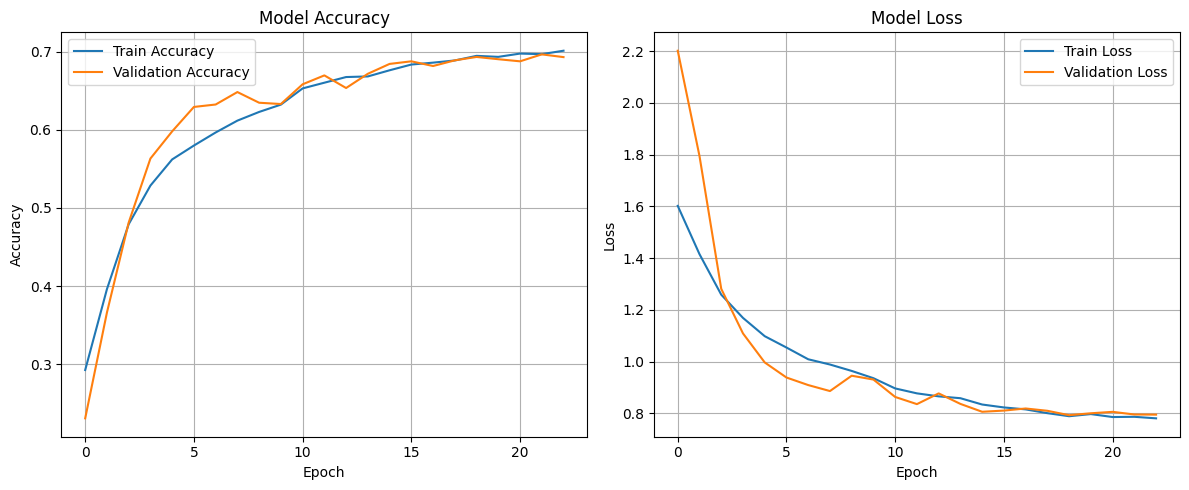

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# نمودار دقت
plt.subplot(1, 2, 1)
plt.plot(histry.history["accuracy"], label="Train Accuracy")
plt.plot(histry.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# نمودار خطا
plt.subplot(1, 2, 2)
plt.plot(histry.history["loss"], label="Train Loss")
plt.plot(histry.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [10]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Loss: {test_loss:.4f}")

95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.6977 - loss: 0.7738
Test Accuracy: 69.77%
Test Loss: 0.7738


In [11]:
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in test_ds
])

print(classification_report(
    y_true,
    y_pred,
    target_names=["angry", "happy", "neutral", "sad", "surprise"],
    zero_division=0
))

              precision    recall  f1-score   support

       angry       0.61      0.61      0.61       958
       happy       0.86      0.83      0.85      1774
     neutral       0.54      0.73      0.62      1233
         sad       0.64      0.48      0.55      1247
    surprise       0.85      0.80      0.83       831

    accuracy                           0.70      6043
   macro avg       0.70      0.69      0.69      6043
weighted avg       0.71      0.70      0.70      6043



In [18]:
import shutil
shutil.copy("best_fer_model.keras", "model2_v2_69.keras")

'model2_v2_69.keras'

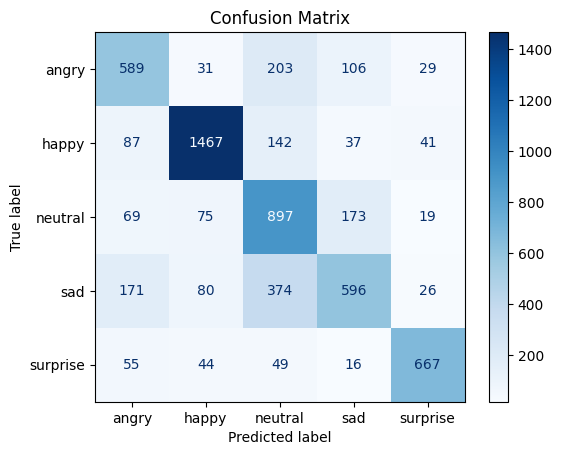

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [14]:
import cv2
from pathlib import Path

Path("my_photos").mkdir(exist_ok=True)   # پوشه my_photos رو می‌سازه

cam = cv2.VideoCapture(0)                # وبکم لپ‌تاپ

for name in ["happy", "sad", "neutral"]:
    print(f"Make a {name} face, then press SPACE to take the photo")
    while True:
        ok, frame = cam.read()
        cv2.putText(frame, f"{name}: press SPACE", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        cv2.imshow("capture", frame)
        if cv2.waitKey(1) & 0xFF == ord(" "):
            cv2.imwrite(f"my_photos/{name}.jpg", frame)
            break

cam.release()
cv2.destroyAllWindows()

KeyboardInterrupt: 

In [15]:
import json
import cv2
import numpy as np
import keras

CLASSES = ["angry", "happy", "neutral", "sad", "surprise"]  # same order as training
model = keras.models.load_model("model_v2_69.keras")
cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def predict_mood(path):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = cascade.detectMultiScale(gray, 1.3, 5)
    if len(faces) > 0:
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])  # biggest face
        gray = gray[y:y + h, x:x + w]

    gray = cv2.resize(gray, (48, 48)) / 255.0
    arr = gray.reshape(1, 48, 48, 1)

    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return {"mood": CLASSES[idx], "confidence": round(float(probs[idx]), 2)}

for name in ["happy", "sad", "neutral"]:
    result = predict_mood(f"my_photos/{name}.jpg")
    print(name, "->", json.dumps(result))

happy -> {"mood": "happy", "confidence": 0.84}
sad -> {"mood": "neutral", "confidence": 0.7}
neutral -> {"mood": "neutral", "confidence": 0.82}


In [16]:
print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    zero_division=0
))

              precision    recall  f1-score   support

       angry       0.61      0.61      0.61       958
       happy       0.86      0.83      0.85      1774
     neutral       0.54      0.73      0.62      1233
         sad       0.64      0.48      0.55      1247
    surprise       0.85      0.80      0.83       831

    accuracy                           0.70      6043
   macro avg       0.70      0.69      0.69      6043
weighted avg       0.71      0.70      0.70      6043

